In [142]:
from sklearn.datasets import load_diabetes
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import PowerTransformer

In [143]:
X,y = load_diabetes(return_X_y= True)

In [144]:
from sklearn.model_selection import train_test_split
X_train,X_test,Y_train,Y_test = train_test_split(X,y,test_size=0.2,random_state=2)

In [39]:
df = pd.DataFrame(X,columns=load_diabetes().feature_names)
df['target'] = y
df.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [40]:
df['sex'].value_counts()
df['sex'] = df['sex'].apply(lambda x : 1 if (x>0) else 0 )



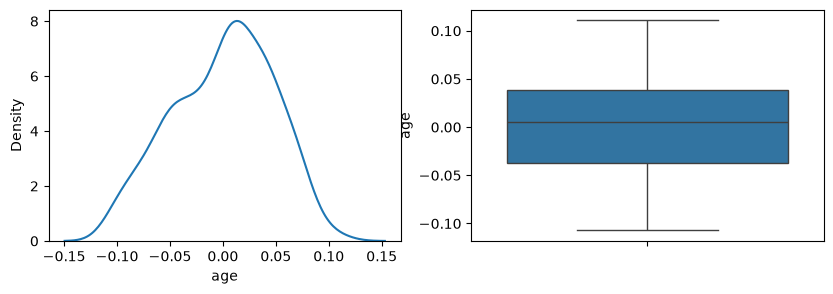

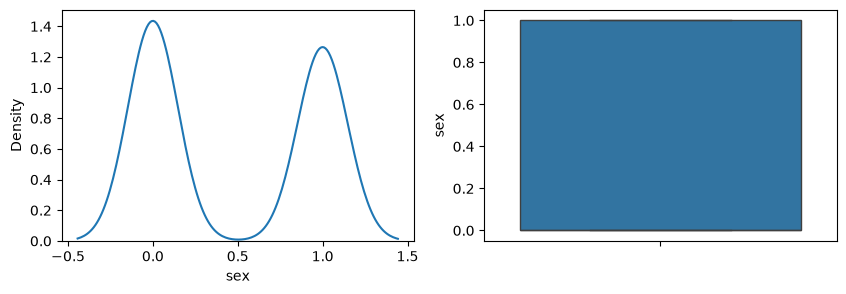

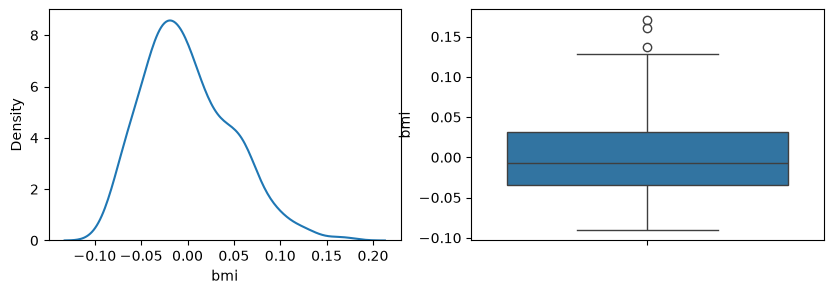

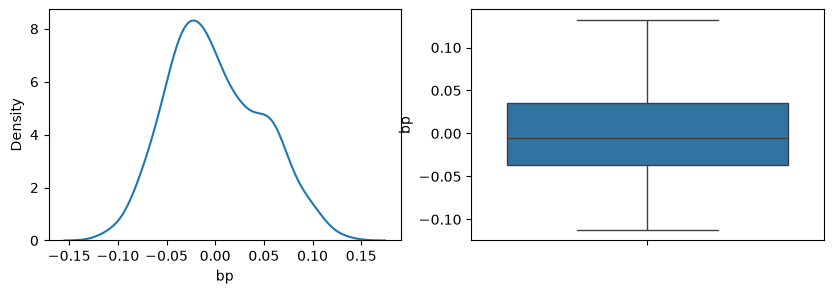

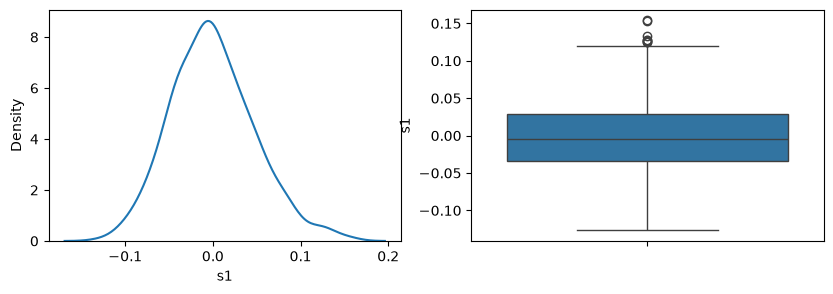

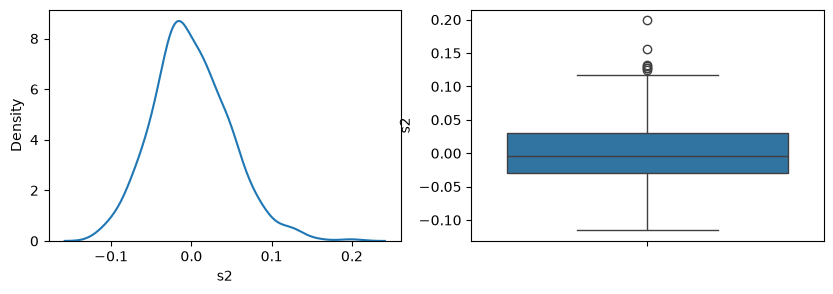

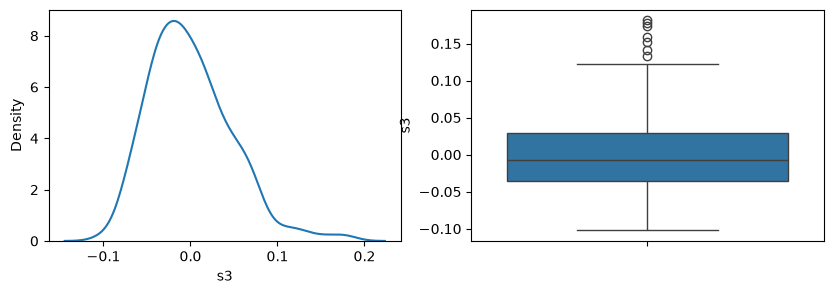

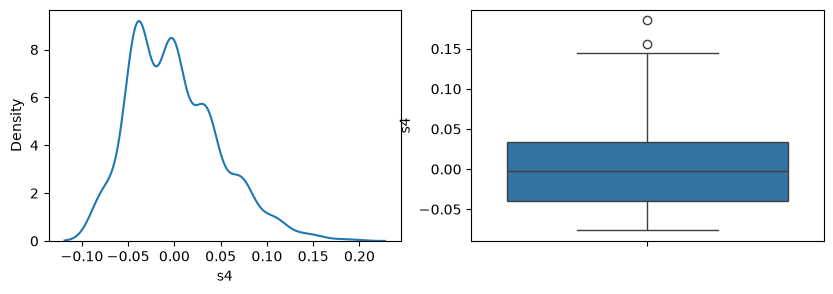

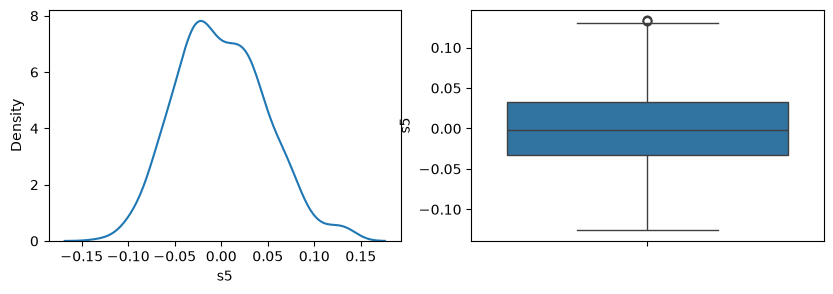

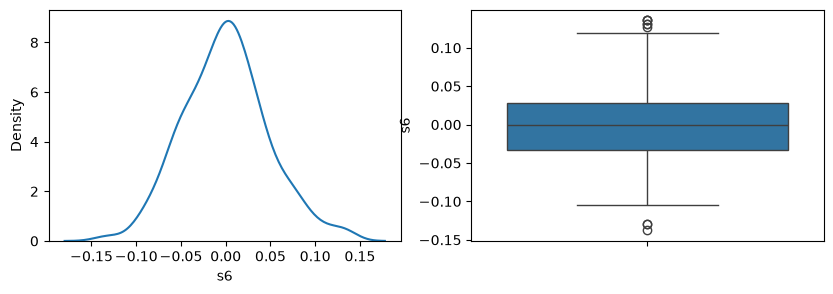

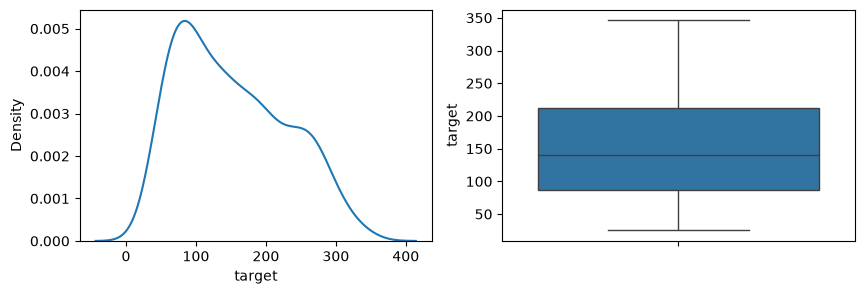

In [41]:
for i in df.select_dtypes('number'):
    plt.figure(figsize=(10,3))
    plt.subplot(1,2,1)
    sns.kdeplot(df[i])
    plt.subplot(1,2,2)
    sns.boxplot(df[i])

<Axes: >

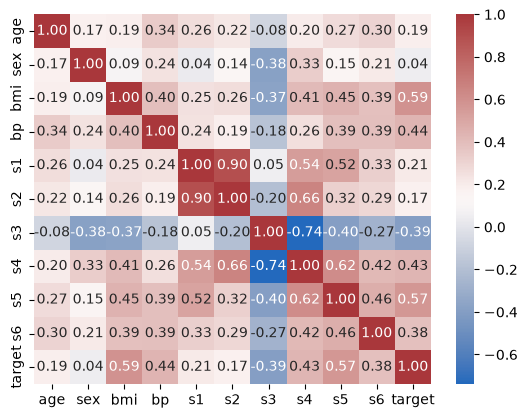

In [42]:
sns.heatmap(df.corr(),annot=True,fmt='.2f',cmap="vlag")

In [46]:
pi = PowerTransformer(method='yeo-johnson')

In [47]:
df['target'] = pi.fit_transform(df[['target']])


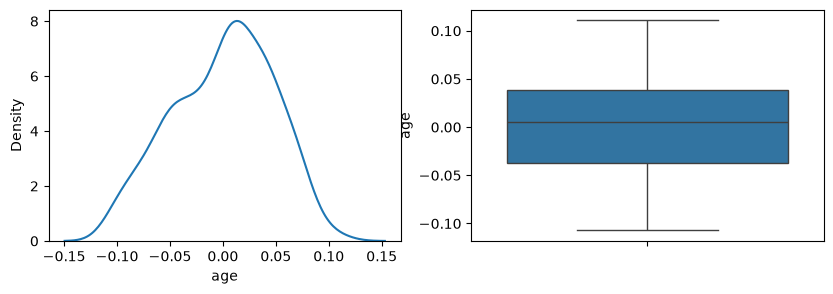

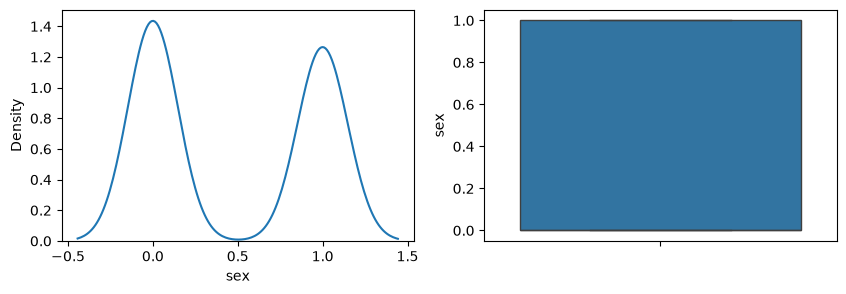

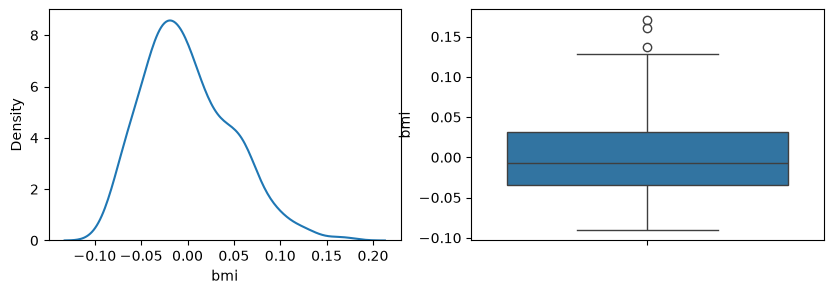

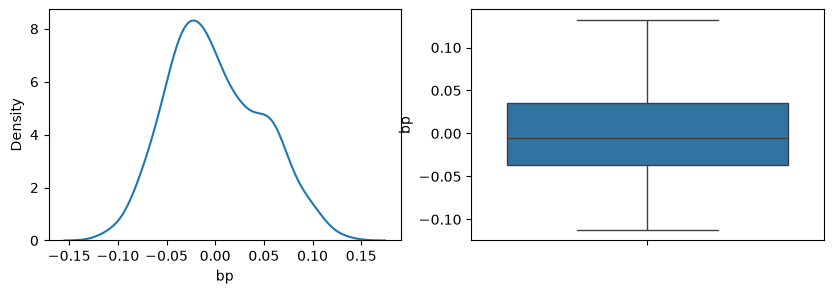

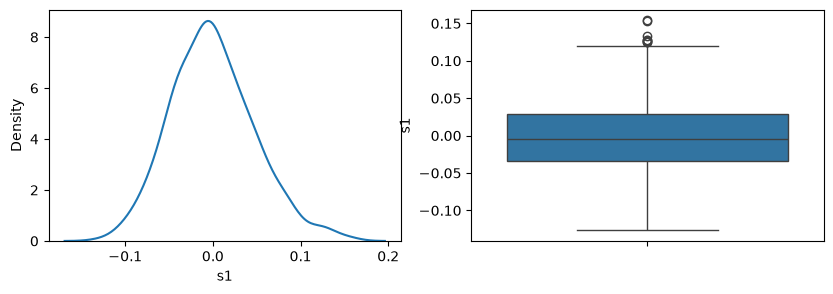

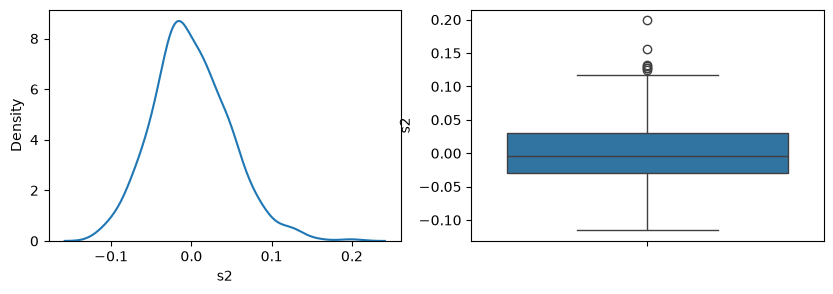

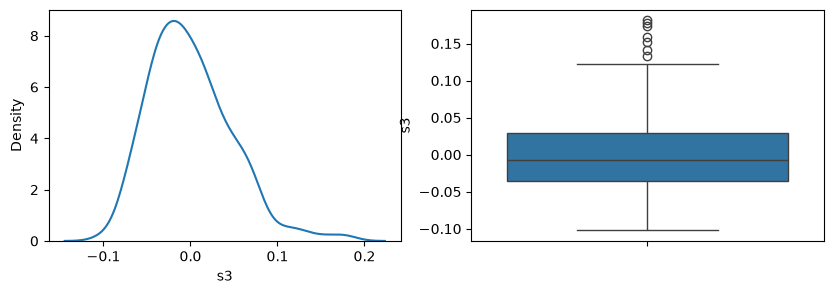

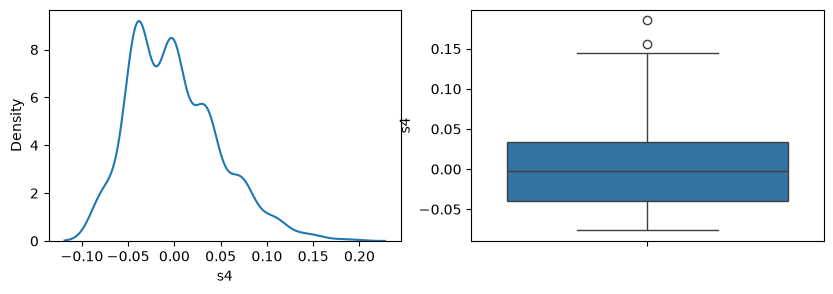

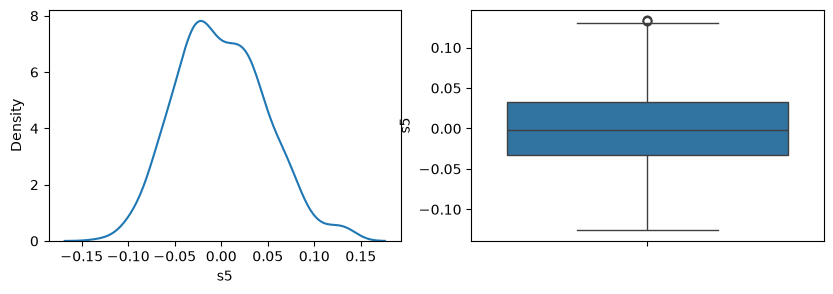

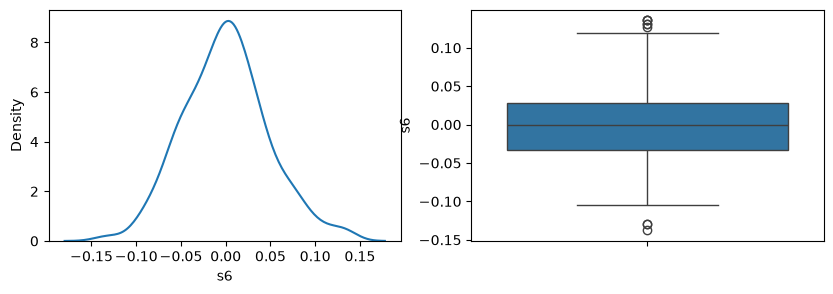

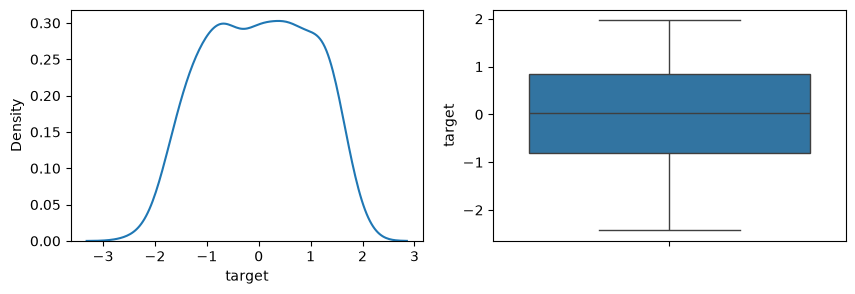

In [48]:
for i in df.select_dtypes('number'):
    plt.figure(figsize=(10,3))
    plt.subplot(1,2,1)
    sns.kdeplot(df[i])
    plt.subplot(1,2,2)
    sns.boxplot(df[i])

In [49]:
from sklearn.linear_model import LinearRegression

In [50]:
li = LinearRegression()

In [51]:
li.fit(X_train,Y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](10,)","[ -9.16,-205.45, 516.69,..., 126.73, 861.13, 52.42]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,151.9
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,10
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(10)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](10,)","[1.79,1.1 ,0.98,...,0.58,0.24,0.08]"


In [52]:
from sklearn.metrics import r2_score
r2_score(Y_test,li.predict(X_test))

0.43993386615689667

In [53]:
li.coef_

array([  -9.15865318, -205.45432163,  516.69374454,  340.61999905,
       -895.5520019 ,  561.22067904,  153.89310954,  126.73139688,
        861.12700152,   52.42112238])

In [54]:
li.intercept_

np.float64(151.88331005254167)

In [56]:
from sklearn.metrics import mean_absolute_error,mean_squared_error
print("RMSE", np.sqrt(mean_squared_error(Y_test,li.predict(X_test))))
print("MAE",mean_absolute_error(Y_test,li.predict(X_test)))
print("MSE", mean_squared_error(Y_test,li.predict(X_test)))

RMSE 55.62784079546916
MAE 45.21303419046903
MSE 3094.4566715660635


In [173]:
alpha = [0,0.001,0.005, 0.01, 0.1,0.18,0.19,0.2, 1, 10, 100, 1000]

In [174]:
from sklearn.linear_model import Ridge,Lasso,ElasticNet
r2 = [];
coef = []

In [175]:
for i in alpha:
    r = Ridge(alpha=i)
    r.fit(X_train,Y_train)
    y_pred = r.predict(X_test)
    print("------------------- alpha :",i,"--------------")
    print("r2 : ",r2_score(Y_test,y_pred))
    r2.append(r2_score(Y_test,y_pred))
    coef.append(np.linalg.norm(r.coef_))
    print("MSE", mean_squared_error(Y_test,y_pred))
    print("RMSE",np.sqrt(mean_squared_error(Y_test,y_pred)))
    print("MAE", mean_absolute_error(Y_test,y_pred))
    
    print("---------------------------------------------")
    
    


------------------- alpha : 0 --------------
r2 :  0.43993386615689645
MSE 3094.456671566065
RMSE 55.627840795469176
MAE 45.21303419046902
---------------------------------------------
------------------- alpha : 0.001 --------------
r2 :  0.4408617113920026
MSE 3089.330175417738
RMSE 55.58174318441027
MAE 45.2282706455472
---------------------------------------------
------------------- alpha : 0.005 --------------
r2 :  0.4427703045294398
MSE 3078.784887262353
RMSE 55.48679921623118
MAE 45.263109688579554
---------------------------------------------
------------------- alpha : 0.01 --------------
r2 :  0.4439392894728015
MSE 3072.3260549238867
RMSE 55.42856713756803
MAE 45.28894572899481
---------------------------------------------
------------------- alpha : 0.1 --------------
r2 :  0.45199494197195456
MSE 3027.817261919799
RMSE 55.02560551161431
MAE 45.40403801924985
---------------------------------------------
------------------- alpha : 0.18 --------------
r2 :  0.453617627241

In [90]:
coef

[np.float64(1404.2102257291601),
 np.float64(1021.9370492090312),
 np.float64(808.5406796526462),
 np.float64(480.7879543972891),
 np.float64(124.25864857692525),
 np.float64(15.410144568374161),
 np.float64(1.58026178574071)]

In [91]:
r2

[0.4408617113920026,
 0.4439392894728015,
 0.45199494197195456,
 0.4078252224517157,
 0.15214327672566985,
 0.010378115936827137,
 -0.010136670498663625]

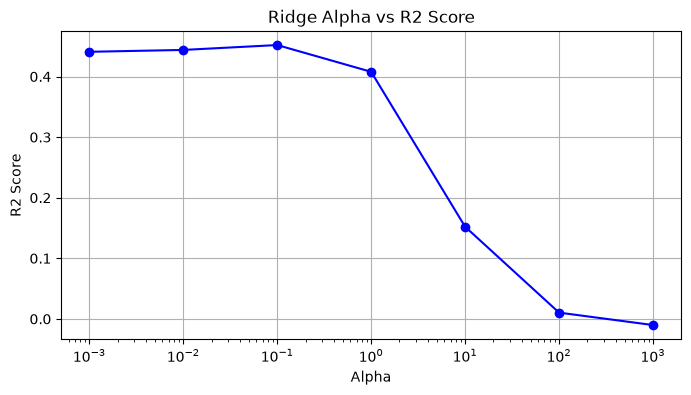

In [84]:
plt.figure(figsize=(8, 4))
plt.plot(alpha, r2, marker='o', linestyle='-', color='b')  # plt.scatter ki jagah plt.plot use karein
plt.xscale('log')  # Kyunki alpha values 0.001 se 1000 tak hain, isliye log scale zaroori hai
plt.xlabel('Alpha')
plt.ylabel('R2 Score')
plt.title('Ridge Alpha vs R2 Score')
plt.grid(True)
plt.show()

Text(0, 0.5, 'alpha')

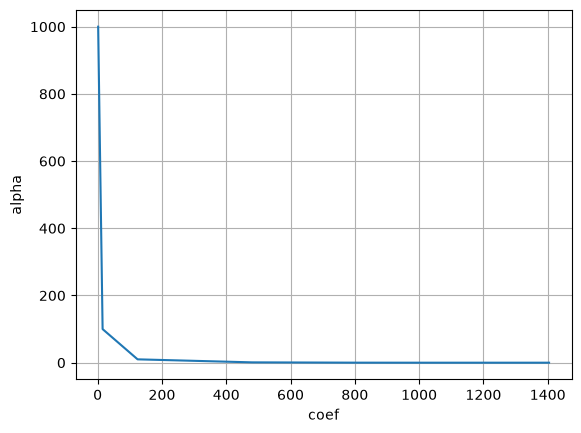

In [92]:
plt.plot(coef,alpha)
plt.grid(True)
plt.xlabel('coef')
plt.ylabel('alpha')

array([[-0.00188202, -0.04464164, -0.06979687, ..., -0.03949338,
        -0.06291688,  0.04034337],
       [-0.00914709, -0.04464164,  0.01103904, ..., -0.03949338,
         0.01703607, -0.0052198 ],
       [ 0.02354575,  0.05068012, -0.02021751, ..., -0.03949338,
        -0.09643495, -0.01764613],
       ...,
       [ 0.06350368,  0.05068012, -0.00405033, ..., -0.00259226,
         0.08449153, -0.01764613],
       [-0.05273755,  0.05068012, -0.01806189, ...,  0.1081111 ,
         0.03606033, -0.04249877],
       [ 0.00175052,  0.05068012,  0.05954058, ...,  0.1081111 ,
         0.06898589,  0.12732762]], shape=(353, 10))

In [190]:
alpha = [0,0.0001, 0.001,0.005,0.0075,0.01,0.05,0.09, 0.1,0.15,0.2,0.5, 1, 10, 100]
coefMag = []
r2l = []
no_of_zeros = []

In [191]:
for i in alpha:
    if(i != 'target'):
        l = Lasso(alpha = i)
        l.fit(X_train,Y_train)
        y_pred = l.predict(X_test)
        r2l.append(r2_score(Y_test,y_pred))
        
        coefMag.append(np.linalg.norm(l.coef_))
        arr = l.coef_
        count = 0
        for j in arr:
            
            if(j == 0):
                count+=1
        
        no_of_zeros.append(count)
        print("------------------- alpha :",i,"--------------")
        print(l.coef_)
        print("no of jinda features :",len(arr) - count)
        print("no of zeros :",count)
        print("r2 : ",r2_score(Y_test,y_pred))
        print("MSE", mean_squared_error(Y_test,y_pred))
        print("RMSE",np.sqrt(mean_squared_error(Y_test,y_pred)))
        print("MAE", mean_absolute_error(Y_test,y_pred))
    
    print("---------------------------------------------")
    

------------------- alpha : 0 --------------
[  -9.15777835 -205.41296398  516.78111164  340.59797977 -890.75243603
  557.46498384  151.75943653  126.11238845  859.35031608   52.4180594 ]
no of jinda features : 10
no of zeros : 0
r2 :  0.4399715467387547
MSE 3094.248480209948
RMSE 55.625969476584835
MAE 45.2137313402742
---------------------------------------------
------------------- alpha : 0.0001 --------------
[  -9.06906443 -205.32940644  516.78941848  340.53237885 -888.66090377
  555.95858353  150.5936554   125.45014323  858.64554075   52.3802936 ]
no of jinda features : 10
no of zeros : 0
r2 :  0.4399732201362009
MSE 3094.23923441632
RMSE 55.625886369713875
MAE 45.21469300776223
---------------------------------------------
------------------- alpha : 0.001 --------------
[  -8.26276976 -204.20536429  517.65007282  339.7439007  -826.6636033
  508.61739504  120.90860746  113.92177296  836.32075334   52.01284899]
no of jinda features : 10
no of zeros : 0
r2 :  0.44030096069159674


C:\Users\HP\anaconda3\Lib\site-packages\sklearn\base.py:1403: UserWarning: With alpha=0, this algorithm does not converge well. You are advised to use the LinearRegression estimator
  return fit_method(estimator, *args, **kwargs)


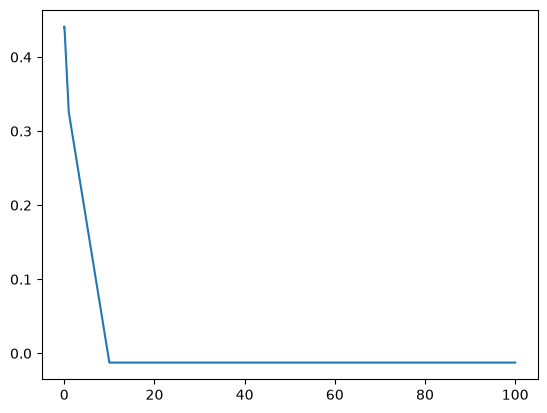

In [124]:
plt.plot(alpha,r2l)

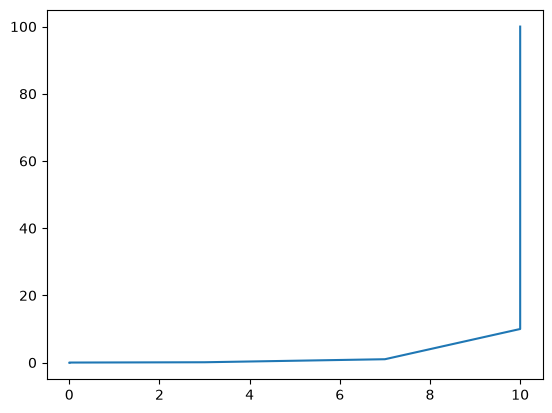

In [125]:
plt.plot(no_of_zeros,alpha)

In [130]:
l1_ratio = [0,0.1, 0.3, 0.5, 0.7, 0.9,1]



In [203]:
for i in l1_ratio:
    en = ElasticNet(alpha= 0.001,l1_ratio=i)
    en.fit(X_train,Y_train)
    y_pred = en.predict(X_test)
    print("------------------- l1_ratio :",i,"--------------")
    print(en.coef_)
    # print("no of jinda features :",len(arr) - count)
    # print("no of zeros :",count)
    
    print("r2 : ",r2_score(Y_test,y_pred))
    print("MSE", mean_squared_error(Y_test,y_pred))
    print("RMSE",np.sqrt(mean_squared_error(Y_test,y_pred)))
    print("MAE", mean_absolute_error(Y_test,y_pred))

------------------- l1_ratio : 0 --------------
[  26.7003999  -120.29034841  399.18266738  267.83847634  -17.01486328
  -68.78847242 -167.54453168  101.57528057  374.18214283   94.68628644]
r2 :  0.44902764255055394
MSE 3044.2120748467655
RMSE 55.1743787898583
MAE 46.03415769244281
------------------- l1_ratio : 0.1 --------------
[  24.72211154 -126.0653389   409.05868595  273.38757275  -20.67761156
  -72.39222362 -169.36458019  100.488122    384.84197228   93.09440211]
r2 :  0.4505171561801117
MSE 3035.9822692758676
RMSE 55.09974835946048
MAE 45.873502338911614
------------------- l1_ratio : 0.3 --------------
[  20.08494336 -138.84491036  430.63474385  285.32623529  -29.84287758
  -79.40910556 -172.79441759   97.3999415   409.21504      88.9007313 ]
r2 :  0.45275021870578847
MSE 3023.6442348669875
RMSE 54.98767348112654
MAE 45.59788591407542
------------------- l1_ratio : 0.5 --------------
[  14.32128608 -153.46010197  455.09600266  298.53152521  -43.42373901
  -84.61018905 -175.4

In [204]:
alphas = ['-','0.19','0.005','0.001']
l1 = ['-','-','-','0.5']
R2 = ['0.4439','0.4535','0.4400','0.4535']
mae = ['45','45','45.29','45.46']


In [207]:
import pandas as pd

data = {
    'Model': ['Linear Regression', 'Ridge', 'Lasso', 'Elastic Net'],
    'Best Alpha': ['-', '0.19', '0.005', '0.001'],
    'Best L1 Ratio': ['-', '-', '-', '0.5'],
    'R²': ['0.4439', '0.4535', '0.4400', '0.4535'],
    'MAE': ['45', '45', '45.29', '45.46'],
    'RMSE': ['55.62', '54.94', '55.48', '55.09']
}

df_results = pd.DataFrame(data)
df_results

,Model,Best Alpha,Best L1 Ratio,R²,MAE,RMSE
0,Linear Regression,-,-,0.4439,45,55.62
1,Ridge,0.19,-,0.4535,45,54.94
2,Lasso,0.005,-,0.4400,45.29,55.48
3,Elastic Net,0.001,0.5,0.4535,45.46,55.09


In [209]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import ElasticNet

# 1. Jin parameters ko test karna hai unki dictionary banayein
param_grid = {
    'alpha': [0.0001, 0.001, 0.005 ,0.01, 0.1, 0.18, 0.19, 0.2, 1, 10],
    'l1_ratio': [0, 0.1, 0.3, 0.5, 0.7, 0.9, 1.0]
}

# 2. ElasticNet model initialize karein
en_model = ElasticNet(max_iter=10000)

# 3. GridSearchCV setup karein (cv=5 matlab 5-fold cross validation)
grid_search = GridSearchCV(estimator=en_model, param_grid=param_grid, scoring='r2', cv=5, n_jobs=-1)

# 4. Train data par fit karein
grid_search.fit(X_train, Y_train)

# 5. Best parameters aur best score print karein
print("Best Hyperparameters found:", grid_search.best_params_)
print("Best R² Score on Train/CV:", grid_search.best_score_)

# Best model ko test data par evaluate karein
best_model = grid_search.best_estimator_
y_pred_best = best_model.predict(X_test)

print("Test R² Score with Best Model:", r2_score(Y_test, y_pred_best))
print("Test RMSE:", np.sqrt(mean_squared_error(Y_test, y_pred_best)))
print("Test MAE:", mean_absolute_error(Y_test, y_pred_best))

Best Hyperparameters found: {'alpha': 0.1, 'l1_ratio': 1.0}
Best R² Score on Train/CV: 0.4908581689021571
Test R² Score with Best Model: 0.4334618007658304
Test RMSE: 55.94833230488522
Test MAE: 46.02043377444822


In [210]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import ElasticNet
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import numpy as np

# 1. Aapke diye gaye parameters
param_grid = {
    'alpha': [0.0001, 0.001, 0.01, 0.1, 1, 10],
    'l1_ratio': [0.1, 0.3, 0.5, 0.7, 0.9]
}

# 2. ElasticNet model initialize karein
en_model = ElasticNet(max_iter=10000)

# 3. GridSearchCV setup karein (cv=5 matlab 5-fold cross validation)
grid_search = GridSearchCV(estimator=en_model, param_grid=param_grid, scoring='r2', cv=5, n_jobs=-1)

# 4. Train data par fit karein
grid_search.fit(X_train, Y_train)

# 5. Results print karein
print("Best Hyperparameters found:", grid_search.best_params_)
print("Best R² Score on Cross-Validation:", grid_search.best_score_)

# Best model ko test data par evaluate karein
best_model = grid_search.best_estimator_
y_pred_best = best_model.predict(X_test)

print("\n--- Test Set Performance ---")
print("Test R² Score:", r2_score(Y_test, y_pred_best))
print("Test RMSE:", np.sqrt(mean_squared_error(Y_test, y_pred_best)))
print("Test MAE:", mean_absolute_error(Y_test, y_pred_best))

Best Hyperparameters found: {'alpha': 0.001, 'l1_ratio': 0.9}
Best R² Score on Cross-Validation: 0.4894569579836883

--- Test Set Performance ---
Test R² Score: 0.44722708783298726
Test RMSE: 55.26445904126612
Test MAE: 45.36468676966639
